# Sarthi - Scheme Data Quality & Cleaning Report

**Goal:** check the scraped master list (`ai/data/raw/sarthi_master_schemes.csv`, 750 schemes) before the
eligibility engine (F4), search (F3) and document checklist (F7) depend on it.

This notebook re-runs the cleaning pipeline (`ai/sarthi_ai/`) and explains each problem it finds and fixes.
Re-run top to bottom after changing the CSV or the rules in `ai/sarthi_ai/taxonomy.py`.

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

AI_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "ai"
sys.path.insert(0, str(AI_DIR))
from sarthi_ai.pipeline import run

AS_OF = date(2026, 11, 13)  # fixed so the report is reproducible
result = run(as_of=AS_OF)
raw = pd.DataFrame(result.raw_rows)
clean = pd.DataFrame(result.records)
m = result.metrics

BLUE, ORANGE = "#2a78d6", "#eb6834"      # validated categorical slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "axes.grid.axis": "x",
})

def hbar(series, title, xlabel, color=BLUE, fmt="{:.0f}"):
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1))
    bars = ax.barh(s.index, s.values, color=color, height=0.65)
    ax.bar_label(bars, labels=[fmt.format(v) for v in s.values], padding=3, color=MUTED, fontsize=9)
    ax.set_title(title, loc="left", color=INK, fontweight="bold")
    ax.set_xlabel(xlabel)
    plt.tight_layout()
    plt.show()

print(f"{len(raw)} schemes, {raw.shape[1]} columns")

750 schemes, 17 columns


## 1. Eligibility fields are mostly empty

The rule engine needs these fields. A blank becomes **UNKNOWN** (spec F4), so the user sees
"Needs verification" instead of a clear PASS or FAIL.

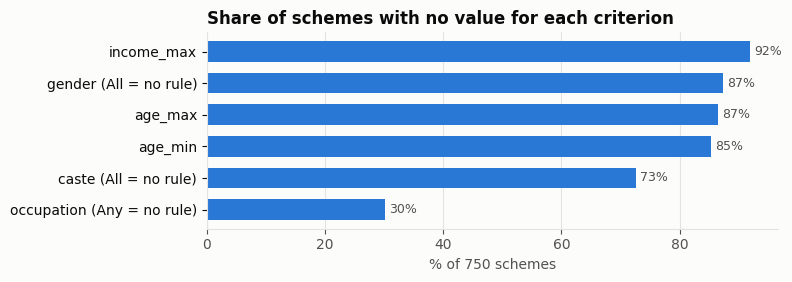

In [2]:
rule_fields = ["age_min", "age_max", "income_max"]
missing = (raw[rule_fields].apply(lambda c: c.str.strip().eq("")).mean() * 100)
missing["gender (All = no rule)"] = raw["gender"].eq("All").mean() * 100
missing["caste (All = no rule)"] = raw["caste_categories"].eq("All").mean() * 100
missing["occupation (Any = no rule)"] = raw["occupations"].eq("Any").mean() * 100
hbar(missing, "Share of schemes with no value for each criterion", "% of 750 schemes", fmt="{:.0f}%")

## 2. Categories were wrong for about half the schemes

Example: *Financial Assistance For The Marriage Of Daughters Of Poor Widows* was filed under
**Agriculture & Farming**. The pipeline fixes categories in three steps:

1. **Keyword rules** (`CATEGORY_RULES` in `taxonomy.py`) - transparent and easy to audit.
2. **ML classifier** - TF-IDF (word + character n-grams) + Logistic Regression, trained on the rows the rules
   label (weak supervision). It covers schemes with no keyword match.
3. **Original label**, kept only when neither of the above is confident.

The accuracy below is measured on hand-labelled samples. The **holdout** sample was labelled after the rules
were frozen, so it is the honest number to report.

In [3]:
ev = m["category_evaluation"]
table = pd.DataFrame({
    name: {k: v["accuracy"] for k, v in ev[name].items() if isinstance(v, dict)}
    for name in ("dev_sample", "holdout_sample")
}).rename(index={
    "original_labels": "Original CSV labels", "rules_then_original": "Rules only",
    "model_only": "ML model only", "final_pipeline": "Final pipeline (rules + model)",
})
table.columns = [f"dev (n={ev['dev_sample']['gold_size']})", f"holdout (n={ev['holdout_sample']['gold_size']})"]
(table * 100).round(1).astype(str) + "%" 

,dev (n=82),holdout (n=44)
Original CSV labels,57.3%,47.7%
Rules only,97.6%,81.8%
ML model only,96.3%,84.1%
Final pipeline (rules + model),97.6%,84.1%


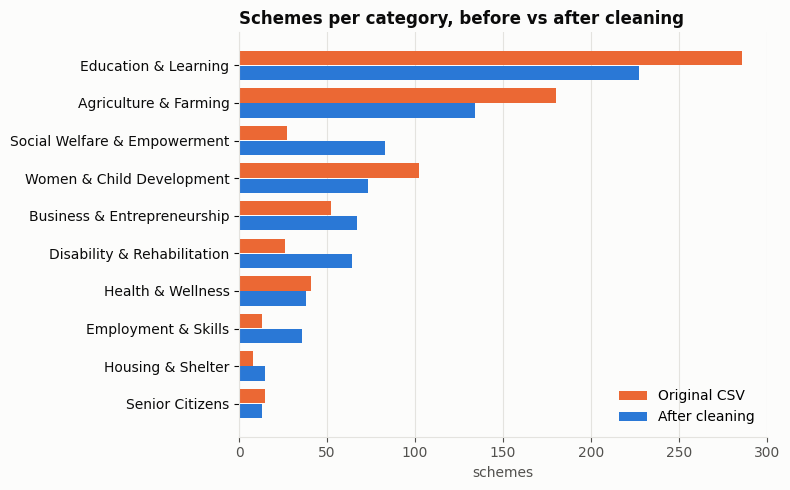

category source: {'original': 145, 'rule': 516, 'model': 89} | changed: 243


In [4]:
before = pd.Series(m["category_before"])
after = pd.Series(m["category_after"])
cats = after.sort_values().index
fig, ax = plt.subplots(figsize=(8, 5))
y = range(len(cats))
ax.barh([i + 0.2 for i in y], before[cats].values, height=0.38, color=ORANGE, label="Original CSV")
ax.barh([i - 0.2 for i in y], after[cats].values, height=0.38, color=BLUE, label="After cleaning")
ax.set_yticks(list(y), cats)
ax.set_title("Schemes per category, before vs after cleaning", loc="left", color=INK, fontweight="bold")
ax.set_xlabel("schemes")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
print("category source:", m["category_source"], "| changed:", m["category_changed"])

In [5]:
# Examples of corrected categories (spot-check these)
changed = clean[clean.category_changed][["id", "name", "category_original", "category", "category_source"]]
changed.sample(12, random_state=1)

,id,name,category_original,category,category_source
259,SCH_0260,Asangathit Karmakaar Mrtyu Evan Divyaang Sahaa...,Disability & Rehabilitation,Social Welfare & Empowerment,rule
747,SCH_0748,Financial Assistance To Dependent Children Of ...,Education & Learning,Women & Child Development,rule
646,SCH_0647,Funeral Assistance (GBOCWWB),Employment & Skills,Social Welfare & Empowerment,rule
433,SCH_0434,Capital Investment Subsidy (for New and Existi...,Women & Child Development,Business & Entrepreneurship,rule
340,SCH_0341,Schemes Of H.P. Backward Classes Finance & Dev...,Agriculture & Farming,Business & Entrepreneurship,model
676,SCH_0677,Financial Assistance For Marriage (APB&OCWWB),Women & Child Development,Social Welfare & Empowerment,rule
224,SCH_0225,Aamar Dukan On Wheels,Education & Learning,Employment & Skills,model
583,SCH_0584,Delhi Pension Scheme To Women In Distress (Wid...,Agriculture & Farming,Women & Child Development,rule
566,SCH_0567,Dr. Muthulakshmi Reddy Ninaivu Inter-caste Mar...,Education & Learning,Social Welfare & Empowerment,rule
33,SCH_0034,Industrial Skill Development Allowance To The ...,Education & Learning,Employment & Skills,rule


## 3. Many "Central" schemes are really state schemes

In 549 rows `applicable_states` is just "Central", and 187 share one identical list of 12 states. The pipeline
finds the real state from the scheme name (e.g. "- West Bengal") or the portal domain (e.g. `gujarat.gov.in`).

{'central': 490, 'state': 260}


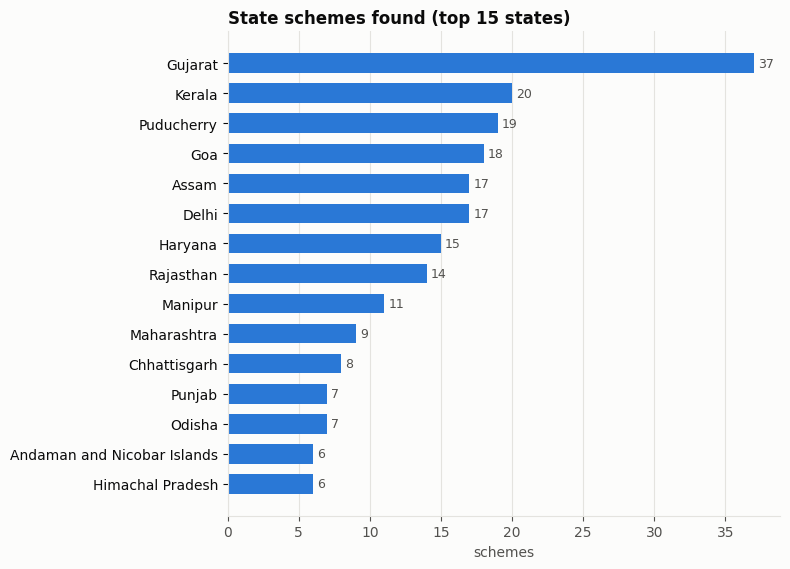

In [6]:
print(m["scope"])
hbar(pd.Series(m["states_inferred"]).head(15), "State schemes found (top 15 states)", "schemes")

## 4. Documents: 1,022 raw strings reduced to a clean checklist

Raw `documents_required` cells mix standard documents with scraped sentence fragments (*"required."*,
*"Whom should I contact ..."*). The pipeline maps them to 21 standard types, drops fragments, and merges
near-duplicates with fuzzy matching (`rapidfuzz`, token-sort ratio >= 88). The F7 checklist uses this output.

raw distinct strings: 1022 -> standard types: 21, other types after merge: 199, fragments dropped: 579


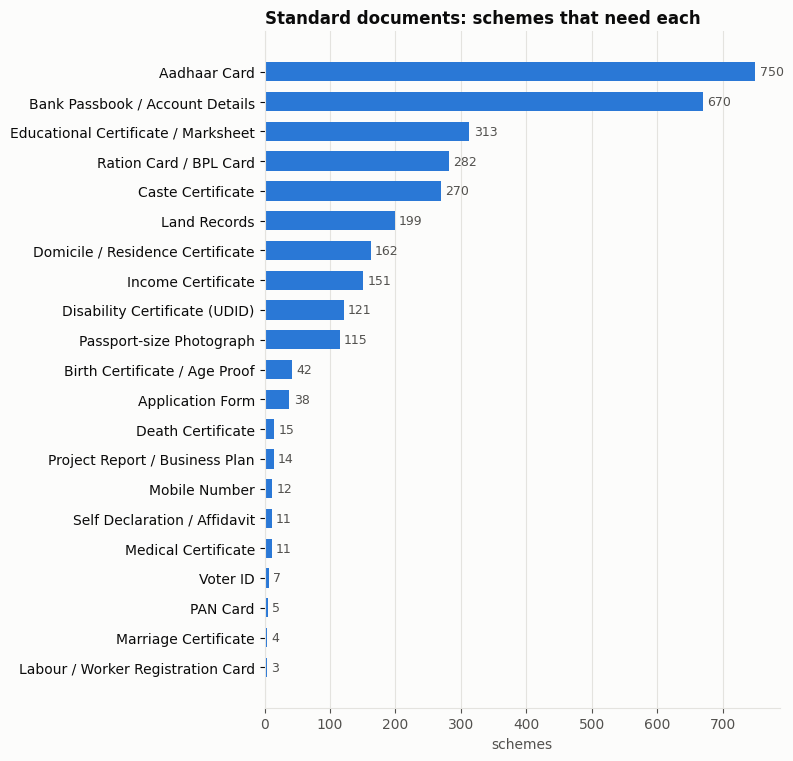

In [7]:
d = m["documents"]
print(f"raw distinct strings: {d['raw_distinct_strings']} -> standard types: {d['standard_types']}, "
      f"other types after merge: {d['other_types_after_merge']}, fragments dropped: {d['dropped_fragment']}")
docs = pd.DataFrame(result.document_types)
hbar(docs[docs.standard].set_index("name")["scheme_count"], "Standard documents: schemes that need each",
     "schemes")

## 5. Freshness and links

The spec (F6/F16) asks for an official link and a recent verified date on every scheme.

In [8]:
fresh = clean["last_verified_date"].value_counts().sort_index()
print("last_verified_date:", fresh.to_dict())
print(f"stale (> 365 days before {AS_OF}):", int(clean.is_stale.sum()))
print("generic myscheme.gov.in homepage as source:", m["quality_flags"].get("source_url_generic", 0))

last_verified_date: {'2024-03-28': 548, '2026-09-16': 1, '2026-10-17': 201}
stale (> 365 days before 2026-11-13): 548
generic myscheme.gov.in homepage as source: 259


## 6. All quality flags

Every flag is saved per scheme in `quality_flags` (in `ai/output/schemes_clean.json`), so the admin
console (F15) can show a review queue later.

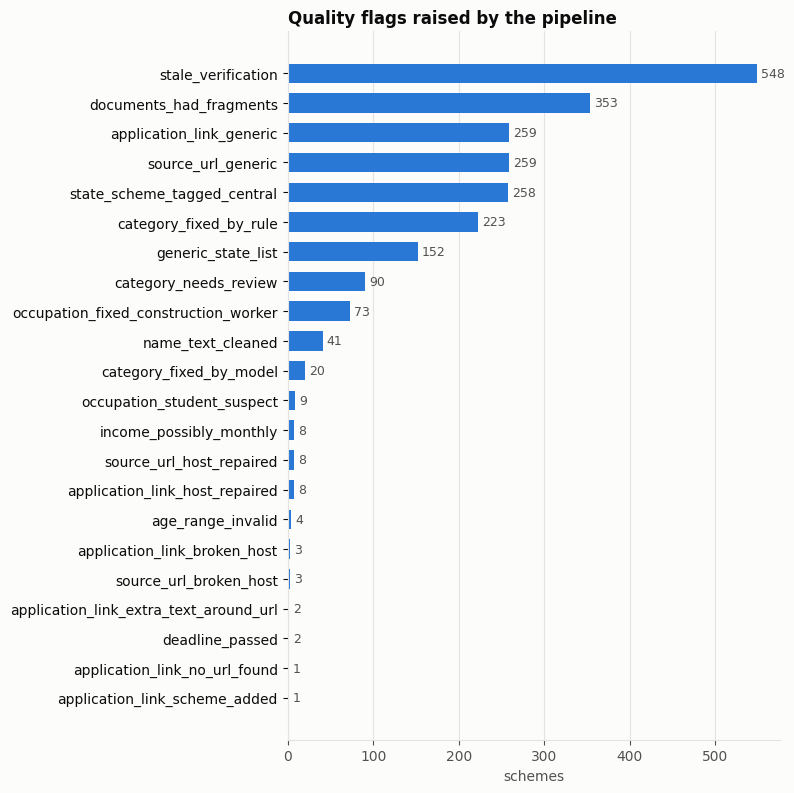

In [9]:
flags = pd.Series(m["quality_flags"])
hbar(flags, "Quality flags raised by the pipeline", "schemes")

## Takeaways

* About half the original categories were wrong. Rules + ML raise holdout accuracy substantially (table in section 2).
* About a third of the schemes were mis-tagged as Central although they belong to one state.
* Most eligibility criteria are blank. Before the F4/F8 demo, fill in the rule fields for the 30-50 demo
  schemes by hand from official sources, as the spec advises.
* `ai/output/category_review.csv` lists every changed or uncertain category, with an empty `reviewer_decision`
  column for the team to fill in.